<a href="https://colab.research.google.com/github/pras736/TugasLibraryProbabilitas/blob/main/Muhammad_Prasetio3TIC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Library Python yang Digunakan

| Library | Fungsi utama | Dipakai untuk |
|---|---|---|
| **NumPy** | Array & bilangan acak (`np.random.default_rng`) | Simulasi percobaan acak |
| **SciPy** (`scipy.stats`) | Distribusi probabilitas: `pmf`, `pdf`, `cdf`, `sf`, `ppf`, `mean`, `var`, `rvs` | Hitung peluang, nilai harapan, varians |
| **SymPy** (`sympy.stats`) | Probabilitas simbolik (hasil eksak) | Peluang teori dadu |
| **Pandas** | Tabel data | Merangkum hasil |
| **Matplotlib** | Grafik dasar | Visualisasi |
| **Seaborn** | Tema & grafik statistik | Tampilan grafik |
| **math** (bawaan) | `comb`, `factorial`, `exp`, `erf` | Hitungan matematis manual |
| **itertools** (bawaan) | `product` | Enumerasi seluruh ruang sampel |
| **fractions** (bawaan) | `Fraction` | Peluang dalam bentuk pecahan eksak |

In [ ]:
import math, itertools
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sympy
from scipy import stats
from scipy.stats import binom, poisson, geom, uniform, expon, norm
from sympy import Eq, Or
from sympy.stats import Die, P

rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid")

print("NumPy", np.__version__, "| SciPy", scipy.__version__, "| SymPy", sympy.__version__, "| Pandas", pd.__version__)


hasil_prob = []
def bandingkan(nama, teori, sim):
    teori, sim = float(teori), float(sim)
    hasil_prob.append({"Soal": nama, "Teori (matematis)": round(teori, 4), "Python / simulasi": round(sim, 4), "Selisih": round(abs(teori - sim), 4)})
    print(f"{nama:<38} teori = {teori:.4f} | python/simulasi = {sim:.4f} | selisih = {abs(teori - sim):.4f}")

ringkasan_dist = []
def catat_dist(nama, e_teori, v_teori, sampel):
    ringkasan_dist.append({"Distribusi": nama, "E[X] teori": round(float(e_teori), 4), "E[X] simulasi": round(float(np.mean(sampel)), 4),
                           "Var(X) teori": round(float(v_teori), 4), "Var(X) simulasi": round(float(np.var(sampel)), 4)})

def plot_diskrit(x, pmf_teori, sampel, judul, xlabel):
    plt.figure(figsize=(7, 4))
    plt.bar(x - 0.2, pmf_teori, width=0.4, label="Teori (pmf)")
    plt.bar(x + 0.2, [np.mean(sampel == k) for k in x], width=0.4, label="Simulasi")
    plt.title(judul); plt.xlabel(xlabel); plt.ylabel("Peluang"); plt.xticks(x); plt.legend(); plt.tight_layout(); plt.show()

def plot_kontinu(xs, pdf_teori, sampel, judul, xlabel):
    plt.figure(figsize=(7, 4))
    plt.hist(sampel, bins=50, density=True, alpha=0.5, label="Simulasi (histogram)")
    plt.plot(xs, pdf_teori, "r", lw=2, label="Teori (pdf)")
    plt.title(judul); plt.xlabel(xlabel); plt.ylabel("Kepadatan"); plt.legend(); plt.tight_layout(); plt.show()

NumPy 2.1.3 | SciPy 1.16.3 | SymPy 1.14.0 | Pandas 2.2.3


---
# BAGIAN A — Permasalahan Probabilitas

## A1. Probabilitas Dasar: Dua Dadu (Level: mudah)

**Soal:** Dua dadu dilempar bersamaan. Berapa peluang jumlah kedua mata dadu = 7?

**Hitungan matematis:** Ruang sampel = 6 × 6 = 36 pasangan. Pasangan berjumlah 7: (1,6), (2,5), (3,4), (4,3), (5,2), (6,1) = 6 pasangan.
P(jumlah = 7) = 6/36 = **1/6 ≈ 0,1667**

Banyak ruang sampel : 36
Kejadian jumlah = 7 : [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]
P(jumlah = 7)       = 1/6
SymPy P(D1 + D2 = 7) = 1/6
A1  P(jumlah dua dadu = 7)             teori = 0.1667 | python/simulasi = 0.1688 | selisih = 0.0022


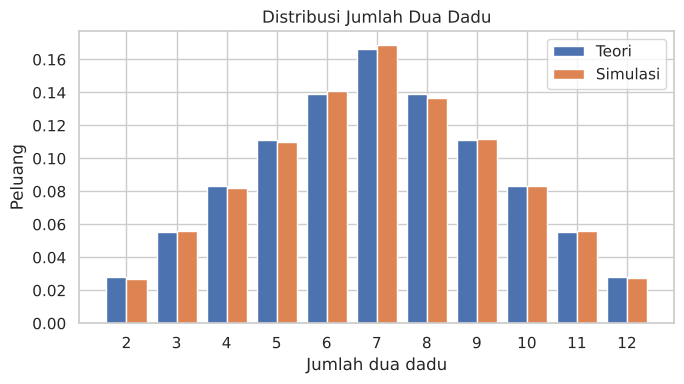

In [ ]:
ruang_sampel = list(itertools.product(range(1, 7), repeat=2))
kejadian = [s for s in ruang_sampel if sum(s) == 7]
p_teori = Fraction(len(kejadian), len(ruang_sampel))
print("Banyak ruang sampel :", len(ruang_sampel))
print("Kejadian jumlah = 7 :", kejadian)
print("P(jumlah = 7)       =", p_teori)

D1, D2 = Die("D1", 6), Die("D2", 6)
print("SymPy P(D1 + D2 = 7) =", P(Eq(D1 + D2, 7)))

n = 100_000
d1 = rng.integers(1, 7, n)
d2 = rng.integers(1, 7, n)
jumlah = d1 + d2
bandingkan("A1  P(jumlah dua dadu = 7)", p_teori, np.mean(jumlah == 7))

nilai = np.arange(2, 13)
teori = [sum(1 for s in ruang_sampel if sum(s) == k) / 36 for k in nilai]
sim = [np.mean(jumlah == k) for k in nilai]
plt.figure(figsize=(7, 4))
plt.bar(nilai - 0.2, teori, 0.4, label="Teori")
plt.bar(nilai + 0.2, sim, 0.4, label="Simulasi")
plt.xlabel("Jumlah dua dadu"); plt.ylabel("Peluang"); plt.title("Distribusi Jumlah Dua Dadu"); plt.xticks(nilai)
plt.legend(); plt.tight_layout(); plt.show()

**Interpretasi:** Peluang teori 1/6 (≈16,67%) dan hasil simulasi hampir sama. Grafik menunjukkan jumlah **7 paling sering muncul** karena punya kombinasi terbanyak (6 dari 36), sedangkan 2 dan 12 paling jarang (1 dari 36).
**Kesimpulan:** Pada ruang sampel yang berhingga dan sama-sama mungkin, peluang = (banyak kejadian)/(banyak ruang sampel), dan simulasi yang cukup besar mengonfirmasinya.

## A2. Kombinasi Kejadian: Union dan Irisan (Level: mudah–sedang)

**Soal:** Satu kartu diambil acak dari 52 kartu. Misal A = kartu Hati, B = kartu King. Hitung P(A ∪ B) dan periksa apakah A dan B saling bebas.

**Hitungan matematis:**
P(A) = 13/52, P(B) = 4/52, P(A ∩ B) = 1/52 (King Hati)
P(A ∪ B) = P(A) + P(B) − P(A ∩ B) = 13/52 + 4/52 − 1/52 = 16/52 = **4/13 ≈ 0,3077**
Bebas jika P(A ∩ B) = P(A)·P(B): (1/4)·(1/13) = 1/52 ✔ → **saling bebas**.

In [ ]:
kartu = [(rank, suit) for rank in range(1, 14) for suit in ["hati", "wajik", "sekop", "keriting"]]
A  = {k for k in kartu if k[1] == "hati"}
B  = {k for k in kartu if k[0] == 13}
pA, pB, pAB = Fraction(len(A), 52), Fraction(len(B), 52), Fraction(len(A & B), 52)

p_union_rumus = pA + pB - pAB
p_union_enum  = Fraction(len(A | B), 52)
print("P(A) =", pA, "| P(B) =", pB, "| P(A∩B) =", pAB)
print("P(A∪B) dengan rumus      =", p_union_rumus)
print("P(A∪B) dengan enumerasi  =", p_union_enum)
print("Saling bebas? P(A∩B) == P(A)*P(B):", pAB == pA * pB)

n = 200_000
idx = rng.integers(0, 52, n)
suit, rank = idx // 13, idx % 13 + 1
hati, king = (suit == 0), (rank == 13)
bandingkan("A2  P(Hati atau King)", p_union_rumus, np.mean(hati | king))
print("Simulasi P(A∩B) =", round(np.mean(hati & king), 4), "| 1/52 =", round(1/52, 4))

P(A) = 1/4 | P(B) = 1/13 | P(A∩B) = 1/52
P(A∪B) dengan rumus      = 4/13
P(A∪B) dengan enumerasi  = 4/13
Saling bebas? P(A∩B) == P(A)*P(B): True
A2  P(Hati atau King)                  teori = 0.3077 | python/simulasi = 0.3102 | selisih = 0.0025
Simulasi P(A∩B) = 0.0194 | 1/52 = 0.0192


**Interpretasi:** Rumus, enumerasi, dan simulasi menghasilkan ≈0,3077. Jika P(A)+P(B) langsung dijumlahkan (tanpa dikurangi irisan) hasilnya 17/52 — King Hati terhitung dua kali. Selain itu, mengetahui kartu itu Hati tidak mengubah peluang kartu itu King, sehingga A dan B **saling bebas**.
**Kesimpulan:** Gunakan P(A∪B) = P(A)+P(B)−P(A∩B); dua kejadian bebas jika peluang irisannya sama dengan hasil kali peluangnya.

## A3. Probabilitas Bersyarat (Level: sedang)

**Soal:** Dua dadu dilempar. Berapa peluang jumlah = 8 **jika diketahui** dadu pertama genap?

**Hitungan matematis:** P(A|B) = P(A ∩ B) / P(B)
B (dadu pertama genap) = 18 pasangan → P(B) = 18/36.
A ∩ B: (2,6), (4,4), (6,2) = 3 pasangan → P(A ∩ B) = 3/36.
P(A|B) = (3/36)/(18/36) = 3/18 = **1/6 ≈ 0,1667**. (Bandingkan P(jumlah=8) tanpa syarat = 5/36 ≈ 0,1389.)

In [ ]:
ruang_sampel = list(itertools.product(range(1, 7), repeat=2))
B  = [s for s in ruang_sampel if s[0] % 2 == 0]
AB = [s for s in B if sum(s) == 8]
p_cond = Fraction(len(AB), len(B))
p_tanpa_syarat = Fraction(len([s for s in ruang_sampel if sum(s) == 8]), 36)
print("Anggota A∩B:", AB)
print("P(jumlah=8 | dadu1 genap) =", p_cond)
print("P(jumlah=8) tanpa syarat  =", p_tanpa_syarat)

n = 300_000
d1 = rng.integers(1, 7, n); d2 = rng.integers(1, 7, n)
syarat = (d1 % 2 == 0)
bandingkan("A3  P(jumlah=8 | dadu1 genap)", p_cond, np.mean((d1 + d2 == 8)[syarat]))

Anggota A∩B: [(2, 6), (4, 4), (6, 2)]
P(jumlah=8 | dadu1 genap) = 1/6
P(jumlah=8) tanpa syarat  = 5/36
A3  P(jumlah=8 | dadu1 genap)          teori = 0.1667 | python/simulasi = 0.1679 | selisih = 0.0012


**Interpretasi:** Setelah tahu dadu pertama genap, peluang jumlah 8 naik dari 5/36 (13,9%) menjadi 1/6 (16,7%) — informasi tambahan **mengubah** peluang, artinya "jumlah = 8" dan "dadu pertama genap" **tidak saling bebas**. Simulasi dengan menyaring percobaan yang memenuhi syarat memberi hasil yang sama.
**Kesimpulan:** Peluang bersyarat = peluang kejadian pada ruang sampel yang sudah dipersempit oleh syarat.

## A4. Teorema Bayes: Filter Spam (Level: sedang, konteks Teknik Informatika)

**Soal:** 40% email adalah spam. Kata "gratis" muncul di 60% email spam dan 5% email bukan spam. Jika sebuah email mengandung kata "gratis", berapa peluang email itu spam?

**Hitungan matematis:**
P(gratis) = P(gratis|spam)·P(spam) + P(gratis|bukan spam)·P(bukan spam) = 0,6·0,4 + 0,05·0,6 = 0,24 + 0,03 = 0,27
P(spam|gratis) = 0,24 / 0,27 = **8/9 ≈ 0,8889**

P(kata 'gratis')    = 0.27
P(spam | 'gratis')  = 0.8889
A4  P(spam | kata 'gratis')            teori = 0.8889 | python/simulasi = 0.8876 | selisih = 0.0013


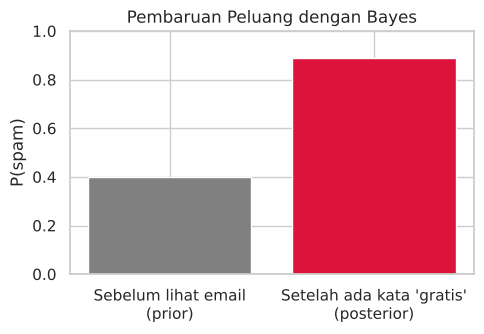

In [ ]:
p_spam, p_k_spam, p_k_ham = 0.4, 0.6, 0.05

p_kata = p_k_spam * p_spam + p_k_ham * (1 - p_spam)
p_bayes = p_k_spam * p_spam / p_kata
print("P(kata 'gratis')    =", round(p_kata, 4))
print("P(spam | 'gratis')  =", round(p_bayes, 4))

n = 500_000
spam = rng.random(n) < p_spam
ada_kata = np.where(spam, rng.random(n) < p_k_spam, rng.random(n) < p_k_ham)
bandingkan("A4  P(spam | kata 'gratis')", p_bayes, np.mean(spam[ada_kata]))

plt.figure(figsize=(5, 3.5))
plt.bar(["Sebelum lihat email\n(prior)", "Setelah ada kata 'gratis'\n(posterior)"], [p_spam, p_bayes], color=["gray", "crimson"])
plt.ylabel("P(spam)"); plt.title("Pembaruan Peluang dengan Bayes"); plt.ylim(0, 1); plt.tight_layout(); plt.show()

**Interpretasi:** Peluang awal sebuah email spam hanya 40%. Begitu ada kata "gratis", peluangnya naik menjadi ≈88,9%. Simulasi (hanya melihat email yang mengandung kata itu) memberi angka yang sama.
**Kesimpulan:** Teorema Bayes dipakai untuk **memperbarui keyakinan** berdasarkan bukti baru — prinsip dasar filter spam Naive Bayes.

## A5. Kombinatorik: Pengambilan Tanpa Pengembalian (Level: sedang)

**Soal:** Lima kartu diambil sekaligus dari 52 kartu. Berapa peluang mendapat **tepat 2 As**?

**Hitungan matematis:** P = C(4,2)·C(48,3) / C(52,5) = (6 × 17.296) / 2.598.960 = 103.776 / 2.598.960 ≈ **0,0399**

In [ ]:
p_teori = math.comb(4, 2) * math.comb(48, 3) / math.comb(52, 5)
print("C(4,2) =", math.comb(4, 2), "| C(48,3) =", math.comb(48, 3), "| C(52,5) =", math.comb(52, 5))
print("P(tepat 2 As) =", round(p_teori, 4))

n = 100_000
hitung = 0
for _ in range(n):
    tangan = rng.choice(52, size=5, replace=False)
    if np.sum(tangan < 4) == 2:
        hitung += 1
bandingkan("A5  P(tepat 2 As dari 5 kartu)", p_teori, hitung / n)

print("Cek SciPy hypergeom :", round(stats.hypergeom.pmf(2, 52, 4, 5), 4))

C(4,2) = 6 | C(48,3) = 17296 | C(52,5) = 2598960
P(tepat 2 As) = 0.0399
A5  P(tepat 2 As dari 5 kartu)         teori = 0.0399 | python/simulasi = 0.0389 | selisih = 0.0010
Cek SciPy hypergeom : 0.0399


**Interpretasi:** Peluang mendapat tepat 2 As dari 5 kartu hanya sekitar 4%. Tiga cara — rumus kombinasi, simulasi, dan `scipy.stats.hypergeom` — memberi angka yang sama.
**Kesimpulan:** Untuk pengambilan **tanpa pengembalian**, gunakan kombinasi (atau distribusi hipergeometrik), bukan binomial.

## A6. Simulasi Percobaan Acak: Masalah Monty Hall (Level: sulit)

**Soal:** Ada 3 pintu: 1 berisi mobil, 2 kambing. Kamu memilih satu pintu, lalu pembawa acara (yang tahu isi pintu) membuka satu pintu **lain** berisi kambing. Apakah lebih baik **tetap** atau **ganti** pilihan?

**Hitungan matematis:**
Peluang pilihan awal benar = 1/3 → strategi **tetap** menang dengan peluang **1/3**.
Jika pilihan awal salah (2/3), pintu sisa yang tidak dibuka pasti mobil → strategi **ganti** menang dengan peluang **2/3**.

A6  Monty Hall - strategi tetap        teori = 0.3333 | python/simulasi = 0.3347 | selisih = 0.0013
A6  Monty Hall - strategi ganti        teori = 0.6667 | python/simulasi = 0.6634 | selisih = 0.0033


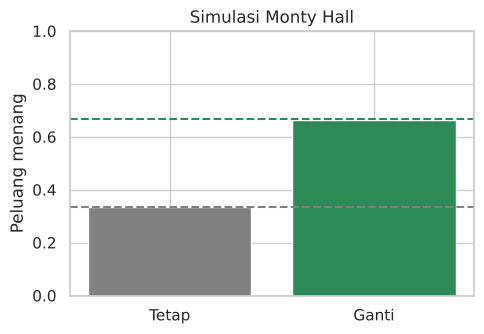

In [ ]:
def monty_hall(ganti):
    mobil, pilih = rng.integers(0, 3, 2)
    buka = rng.choice([d for d in range(3) if d != mobil and d != pilih])
    if ganti:
        pilih = [d for d in range(3) if d != pilih and d != buka][0]
    return pilih == mobil

n = 30_000
menang_tetap = np.mean([monty_hall(False) for _ in range(n)])
menang_ganti = np.mean([monty_hall(True)  for _ in range(n)])
bandingkan("A6  Monty Hall - strategi tetap", 1/3, menang_tetap)
bandingkan("A6  Monty Hall - strategi ganti", 2/3, menang_ganti)

plt.figure(figsize=(5, 3.5))
plt.bar(["Tetap", "Ganti"], [menang_tetap, menang_ganti], color=["gray", "seagreen"])
plt.axhline(1/3, ls="--", c="gray"); plt.axhline(2/3, ls="--", c="seagreen")
plt.ylabel("Peluang menang"); plt.title("Simulasi Monty Hall"); plt.ylim(0, 1); plt.tight_layout(); plt.show()

**Interpretasi:** Simulasi menunjukkan strategi **ganti** menang ≈2/3 dan **tetap** ≈1/3, persis hasil hitungan. Hasil ini sering terasa tidak intuitif karena banyak orang mengira sisa dua pintu peluangnya 50:50 — padahal pembawa acara tidak membuka pintu secara acak, sehingga ia memberi informasi.
**Kesimpulan:** Simulasi berguna untuk memverifikasi soal yang hasilnya bertentangan dengan intuisi. Strategi terbaik: **selalu ganti pintu**.

## A7. Birthday Paradox & Tabrakan Hash (Level: sulit, konteks Teknik Informatika)

**Soal:** Dalam sebuah kelas berisi *n* orang, berapa peluang minimal dua orang berulang tahun di hari yang sama? (Konsep yang sama menjelaskan **tabrakan/collision pada hash**.)

**Hitungan matematis:** Pakai komplemen.
P(semua beda) = (365/365)·(364/365)·…·((365−n+1)/365)
P(minimal ada yang sama) = 1 − P(semua beda). Untuk n = 23: ≈ **0,5073**.

Teori   P(n=23) = 0.5073


A7  Birthday paradox (n=23)            teori = 0.5073 | python/simulasi = 0.5087 | selisih = 0.0014


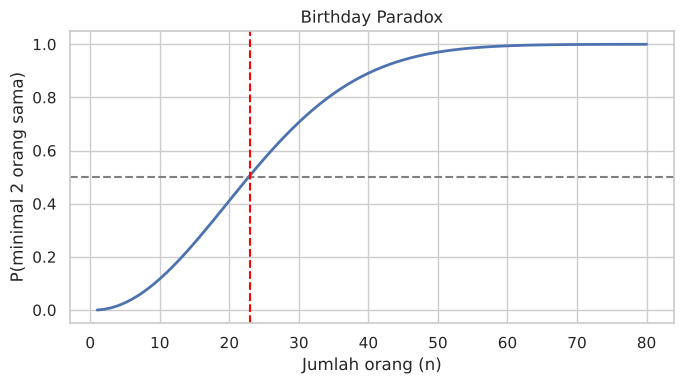

100 data pada 65.536 slot hash -> P(tabrakan) = 0.0728
300 data pada 65.536 slot hash -> P(tabrakan) = 0.4961
500 data pada 65.536 slot hash -> P(tabrakan) = 0.8517


In [ ]:
def p_birthday(n, hari=365):
    p_beda = 1.0
    for i in range(n):
        p_beda *= (hari - i) / hari
    return 1 - p_beda

print("Teori   P(n=23) =", round(p_birthday(23), 4))

n_orang, percobaan = 23, 50_000
hitung = sum(len(set(rng.integers(0, 365, n_orang))) < n_orang for _ in range(percobaan))
bandingkan("A7  Birthday paradox (n=23)", p_birthday(23), hitung / percobaan)

ns = np.arange(1, 81)
plt.figure(figsize=(7, 4))
plt.plot(ns, [p_birthday(k) for k in ns], lw=2)
plt.axhline(0.5, ls="--", c="gray"); plt.axvline(23, ls="--", c="red")
plt.xlabel("Jumlah orang (n)"); plt.ylabel("P(minimal 2 orang sama)"); plt.title("Birthday Paradox")
plt.tight_layout(); plt.show()

for k in [100, 300, 500]:
    print(f"{k} data pada 65.536 slot hash -> P(tabrakan) = {p_birthday(k, 65536):.4f}")

**Interpretasi:** Hanya dengan **23 orang**, peluang ada yang berulang tahun sama sudah melewati 50%. Grafik naik sangat cepat. Pada hash 16-bit (65.536 slot), cukup beberapa ratus data sudah membuat tabrakan sangat mungkin terjadi.
**Kesimpulan:** Tabrakan muncul jauh lebih cepat daripada dugaan intuitif — sebab itu fungsi hash perlu ruang output yang besar.

---
# BAGIAN B — Permasalahan Distribusi Probabilitas

Tiap soal dibandingkan: **rumus manual** ↔ **SciPy** ↔ **simulasi (`rvs`)**, serta dihitung **nilai harapan E[X]** dan **varians Var(X)**.

## B1. Distribusi Binomial (diskrit) — Paket Data Hilang

**Soal:** Sebuah router mengirim 20 paket data. Tiap paket hilang dengan peluang 0,1 (saling bebas). Misal X = banyak paket hilang. Hitung P(X = 2), P(X ≥ 1), E[X], dan Var(X).

**Hitungan matematis:** X ~ Binomial(n=20, p=0,1)
P(X=2) = C(20,2)·0,1²·0,9¹⁸ = 190 × 0,01 × 0,1501 ≈ **0,2852**
P(X≥1) = 1 − 0,9²⁰ ≈ **0,8784**
E[X] = np = **2** ; Var(X) = np(1−p) = **1,8**

Manual : P(X=2) = 0.2852 | P(X>=1) = 0.8784 | E = 2.0 | Var = 1.8
SciPy  : P(X=2) = 0.2852 | P(X>=1) = 0.8784 | E = 2.0 | Var = 1.8
Simulasi: P(X=2) = 0.2853 | P(X>=1) = 0.8796 | E = 2.0041 | Var = 1.7951


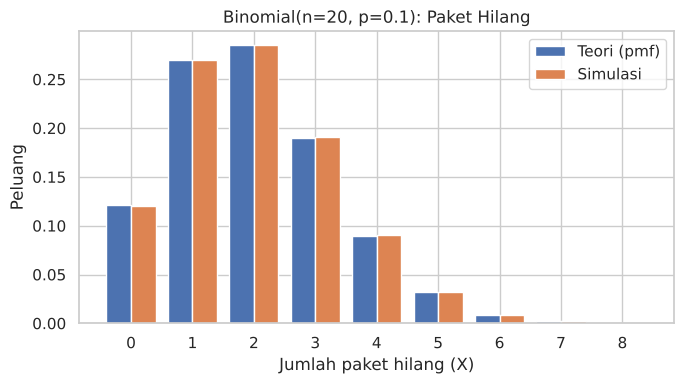

In [ ]:
n, p = 20, 0.1

m2   = math.comb(n, 2) * p**2 * (1 - p)**(n - 2)
mge1 = 1 - (1 - p)**n
print("Manual : P(X=2) =", round(m2, 4), "| P(X>=1) =", round(mge1, 4), "| E =", n*p, "| Var =", round(n*p*(1-p), 4))

print("SciPy  : P(X=2) =", round(binom.pmf(2, n, p), 4), "| P(X>=1) =", round(binom.sf(0, n, p), 4),
      "| E =", binom.mean(n, p), "| Var =", round(binom.var(n, p), 4))

sampel = rng.binomial(n, p, 100_000)
print("Simulasi: P(X=2) =", round(np.mean(sampel == 2), 4), "| P(X>=1) =", round(np.mean(sampel >= 1), 4),
      "| E =", round(sampel.mean(), 4), "| Var =", round(sampel.var(), 4))
catat_dist("Binomial(n=20, p=0.1)", n*p, n*p*(1-p), sampel)

x = np.arange(0, 9)
plot_diskrit(x, binom.pmf(x, n, p), sampel, "Binomial(n=20, p=0.1): Paket Hilang", "Jumlah paket hilang (X)")

**Interpretasi:** Rata-rata ada 2 paket hilang dari 20 kiriman. Peluang tepat 2 paket hilang ≈28,5%, dan peluang **minimal satu** paket hilang ≈87,8% — jadi hampir pasti ada kehilangan di setiap pengiriman 20 paket. Tiga metode memberi hasil yang cocok.
**Kesimpulan:** Binomial cocok untuk menghitung jumlah "sukses/gagal" dari sejumlah percobaan bebas dengan peluang tetap.

## B2. Distribusi Poisson (diskrit) — Request ke Server

**Soal:** Sebuah web server menerima rata-rata 4 request per detik. Hitung peluang tepat 6 request dalam satu detik, dan peluang **lebih dari 8** request (server overload).

**Hitungan matematis:** X ~ Poisson(λ=4)
P(X=6) = e⁻⁴·4⁶/6! = 0,0183 × 4096 / 720 ≈ **0,1042**
P(X>8) = 1 − P(X≤8) ≈ **0,0214**
E[X] = λ = **4** ; Var(X) = λ = **4**

Manual : P(X=6) = 0.1042
SciPy  : P(X=6) = 0.1042 | P(X>8) = 0.0214 | E = 4.0 | Var = 4.0
Simulasi: P(X=6) = 0.1042 | P(X>8) = 0.0218 | E = 3.996 | Var = 4.0078


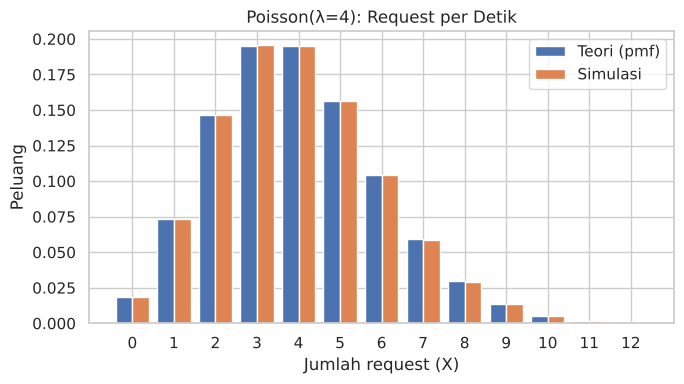

In [ ]:
lam = 4

m6 = math.exp(-lam) * lam**6 / math.factorial(6)
print("Manual : P(X=6) =", round(m6, 4))

print("SciPy  : P(X=6) =", round(poisson.pmf(6, lam), 4), "| P(X>8) =", round(poisson.sf(8, lam), 4),
      "| E =", poisson.mean(lam), "| Var =", poisson.var(lam))

sampel = rng.poisson(lam, 200_000)
print("Simulasi: P(X=6) =", round(np.mean(sampel == 6), 4), "| P(X>8) =", round(np.mean(sampel > 8), 4),
      "| E =", round(sampel.mean(), 4), "| Var =", round(sampel.var(), 4))
catat_dist("Poisson(lambda=4)", lam, lam, sampel)

x = np.arange(0, 13)
plot_diskrit(x, poisson.pmf(x, lam), sampel, "Poisson(λ=4): Request per Detik", "Jumlah request (X)")

**Interpretasi:** Request yang paling sering muncul adalah 3–4 per detik. Peluang lonjakan lebih dari 8 request hanya ≈2,1% — jarang, tetapi pada trafik besar tetap akan terjadi sesekali. Ciri khas Poisson terlihat: **rata-rata = varians = 4**.
**Kesimpulan:** Poisson cocok untuk jumlah kejadian acak per satuan waktu (request, error log, panggilan masuk), dan bisa dipakai untuk merencanakan kapasitas server.

## B3. Distribusi Geometrik (diskrit) — Menemukan Bug Pertama

**Soal:** Setiap uji (test case) menemukan bug dengan peluang 0,2 (saling bebas). Berapa peluang bug **pertama** ditemukan tepat pada uji ke-3, dan peluang bug pertama ditemukan dalam 5 uji pertama?

**Hitungan matematis:** X ~ Geometrik(p=0,2), X = 1, 2, 3, …
P(X=3) = (0,8)²·0,2 = **0,128**
P(X≤5) = 1 − 0,8⁵ = **0,6723**
E[X] = 1/p = **5** ; Var(X) = (1−p)/p² = 0,8/0,04 = **20**

Manual : P(X=3) = 0.128 | P(X<=5) = 0.6723 | E = 5.0 | Var = 20.0
SciPy  : P(X=3) = 0.128 | P(X<=5) = 0.6723 | E = 5.0 | Var = 20.0
Simulasi: P(X=3) = 0.127 | P(X<=5) = 0.6716 | E = 5.0021 | Var = 19.9536


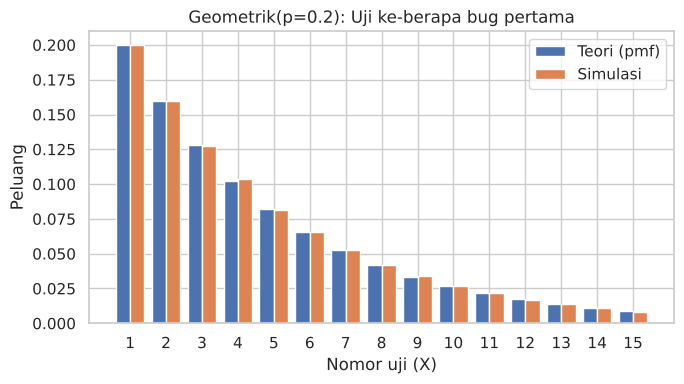

In [ ]:
p = 0.2

print("Manual : P(X=3) =", round((1-p)**2 * p, 4), "| P(X<=5) =", round(1 - (1-p)**5, 4), "| E =", 1/p, "| Var =", round((1-p)/p**2, 4))

print("SciPy  : P(X=3) =", round(geom.pmf(3, p), 4), "| P(X<=5) =", round(geom.cdf(5, p), 4),
      "| E =", geom.mean(p), "| Var =", round(geom.var(p), 4))

sampel = rng.geometric(p, 200_000)
print("Simulasi: P(X=3) =", round(np.mean(sampel == 3), 4), "| P(X<=5) =", round(np.mean(sampel <= 5), 4),
      "| E =", round(sampel.mean(), 4), "| Var =", round(sampel.var(), 4))
catat_dist("Geometrik(p=0.2)", 1/p, (1-p)/p**2, sampel)

x = np.arange(1, 16)
plot_diskrit(x, geom.pmf(x, p), sampel, "Geometrik(p=0.2): Uji ke-berapa bug pertama", "Nomor uji (X)")

**Interpretasi:** Rata-rata dibutuhkan 5 uji untuk menemukan bug pertama. Peluang paling besar justru di uji ke-1 (20%) dan menurun bertahap — distribusi **menceng ke kanan**. Dalam 5 uji pertama, peluang menemukan setidaknya satu bug ≈67%.
**Kesimpulan:** Geometrik memodelkan "berapa percobaan sampai sukses pertama", misalnya jumlah retry sampai koneksi berhasil.

## B4. Distribusi Uniform (kontinu) — Delay Random Backoff

**Soal:** Sebuah protokol jaringan memilih waktu tunggu acak (backoff) secara seragam antara 0 sampai 10 ms. Hitung P(X < 3), P(2 < X < 7), E[X], dan Var(X).

**Hitungan matematis:** X ~ Uniform(0, 10), pdf = 1/10
P(X<3) = 3/10 = **0,3** ; P(2<X<7) = 5/10 = **0,5**
E[X] = (a+b)/2 = **5** ; Var(X) = (b−a)²/12 = 100/12 ≈ **8,3333**

Manual : P(X<3) = 0.3 | P(2<X<7) = 0.5 | E = 5.0 | Var = 8.3333
SciPy  : P(X<3) = 0.3 | P(2<X<7) = 0.5 | E = 5.0 | Var = 8.3333
Simulasi: P(X<3) = 0.3014 | P(2<X<7) = 0.501 | E = 4.9941 | Var = 8.3415


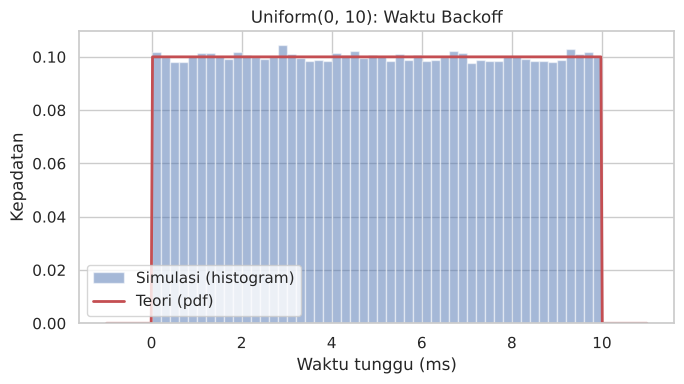

In [ ]:
a, b = 0, 10
dist = uniform(loc=a, scale=b - a)

print("Manual : P(X<3) =", 3/10, "| P(2<X<7) =", 5/10, "| E =", (a+b)/2, "| Var =", round((b-a)**2/12, 4))
print("SciPy  : P(X<3) =", round(dist.cdf(3), 4), "| P(2<X<7) =", round(dist.cdf(7) - dist.cdf(2), 4),
      "| E =", dist.mean(), "| Var =", round(dist.var(), 4))

sampel = rng.uniform(a, b, 200_000)
print("Simulasi: P(X<3) =", round(np.mean(sampel < 3), 4), "| P(2<X<7) =", round(np.mean((sampel > 2) & (sampel < 7)), 4),
      "| E =", round(sampel.mean(), 4), "| Var =", round(sampel.var(), 4))
catat_dist("Uniform(0, 10)", (a+b)/2, (b-a)**2/12, sampel)

xs = np.linspace(-1, 11, 400)
plot_kontinu(xs, dist.pdf(xs), sampel, "Uniform(0, 10): Waktu Backoff", "Waktu tunggu (ms)")

**Interpretasi:** Semua nilai di antara 0–10 ms punya kepadatan yang sama, jadi peluang hanya bergantung pada **lebar interval**: 3 ms → 30%, 5 ms → 50%. Histogram simulasi datar mengikuti garis pdf.
**Kesimpulan:** Uniform dipakai ketika semua hasil dalam rentang dianggap sama mungkin (random backoff, pembangkit bilangan acak).

## B5. Distribusi Eksponensial (kontinu) — Waktu Antar Kegagalan Server

**Soal:** Waktu antar kegagalan sebuah server rata-rata 100 jam (berdistribusi eksponensial). Hitung peluang server bertahan **lebih dari 150 jam** tanpa gagal, dan peluang gagal **sebelum 50 jam**.

**Hitungan matematis:** T ~ Eksponensial dengan mean 100 (λ = 0,01)
P(T>150) = e^(−0,01·150) = e^(−1,5) ≈ **0,2231**
P(T<50) = 1 − e^(−0,5) ≈ **0,3935**
E[T] = 1/λ = **100** ; Var(T) = 1/λ² = **10.000**

Manual : P(T>150) = 0.2231 | P(T<50) = 0.3935 | E = 100.0 | Var = 10000.0
SciPy  : P(T>150) = 0.2231 | P(T<50) = 0.3935 | E = 100.0 | Var = 10000.0
Simulasi: P(T>150) = 0.2223 | P(T<50) = 0.3949 | E = 99.91 | Var = 9981.8


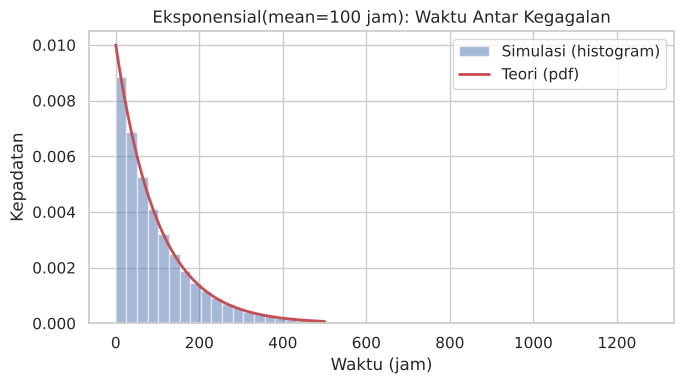

In [ ]:
mean_T = 100
lam = 1 / mean_T
dist = expon(scale=mean_T)

print("Manual : P(T>150) =", round(math.exp(-lam*150), 4), "| P(T<50) =", round(1 - math.exp(-lam*50), 4),
      "| E =", 1/lam, "| Var =", round(1/lam**2, 1))
print("SciPy  : P(T>150) =", round(dist.sf(150), 4), "| P(T<50) =", round(dist.cdf(50), 4),
      "| E =", dist.mean(), "| Var =", round(dist.var(), 1))

sampel = rng.exponential(mean_T, 200_000)
print("Simulasi: P(T>150) =", round(np.mean(sampel > 150), 4), "| P(T<50) =", round(np.mean(sampel < 50), 4),
      "| E =", round(sampel.mean(), 2), "| Var =", round(sampel.var(), 1))
catat_dist("Eksponensial(mean=100)", 1/lam, 1/lam**2, sampel)

xs = np.linspace(0, 500, 500)
plot_kontinu(xs, dist.pdf(xs), sampel, "Eksponensial(mean=100 jam): Waktu Antar Kegagalan", "Waktu (jam)")

**Interpretasi:** Meskipun rata-rata 100 jam, ≈39% server sudah gagal sebelum 50 jam, sedangkan ≈22% mampu bertahan lebih dari 150 jam. Distribusinya **menceng kanan**: banyak kegagalan cepat, sedikit yang sangat awet.
**Kesimpulan:** Eksponensial memodelkan waktu tunggu antar kejadian acak (kegagalan, kedatangan request) dan punya sifat *memoryless*.

## B6. Distribusi Normal (kontinu) — Waktu Respons API

**Soal:** Waktu respons sebuah API berdistribusi normal dengan rata-rata 200 ms dan simpangan baku 30 ms. Hitung P(X > 250), P(170 < X < 230), dan batas waktu respons yang dipenuhi 95% request (persentil ke-95).

**Hitungan matematis:** X ~ N(μ=200, σ=30)
z = (250−200)/30 = 1,667 → P(X>250) = 1 − Φ(1,667) ≈ **0,0478**
170 dan 230 adalah μ ± 1σ → P ≈ **0,6827**
Persentil 95: x = μ + 1,645·σ = 200 + 49,35 ≈ **249,35 ms**

Manual : P(X>250) = 0.0478 | P(170<X<230) = 0.6827
SciPy  : P(X>250) = 0.0478 | P(170<X<230) = 0.6827 | Persentil-95 = 249.35 | E = 200.0 | Var = 900.0


Simulasi: P(X>250) = 0.0476 | P(170<X<230) = 0.6821 | Persentil-95 = 249.29 | E = 200.02 | Var = 901.8


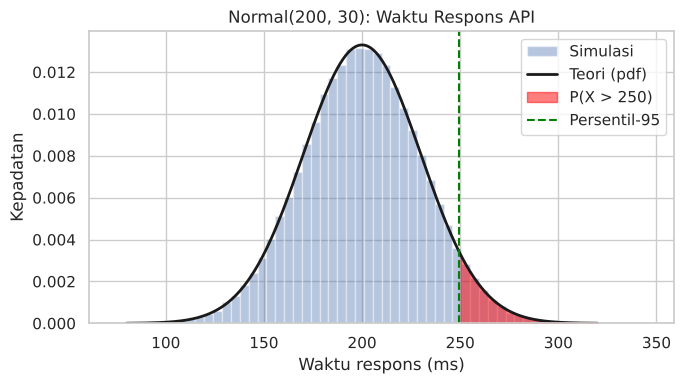

In [ ]:
mu, sigma = 200, 30

def Phi(z): return 0.5 * (1 + math.erf(z / math.sqrt(2)))
print("Manual : P(X>250) =", round(1 - Phi((250-mu)/sigma), 4), "| P(170<X<230) =", round(Phi(1) - Phi(-1), 4))

dist = norm(mu, sigma)
print("SciPy  : P(X>250) =", round(dist.sf(250), 4), "| P(170<X<230) =", round(dist.cdf(230) - dist.cdf(170), 4),
      "| Persentil-95 =", round(dist.ppf(0.95), 2), "| E =", dist.mean(), "| Var =", dist.var())

sampel = rng.normal(mu, sigma, 200_000)
print("Simulasi: P(X>250) =", round(np.mean(sampel > 250), 4), "| P(170<X<230) =", round(np.mean((sampel > 170) & (sampel < 230)), 4),
      "| Persentil-95 =", round(np.percentile(sampel, 95), 2), "| E =", round(sampel.mean(), 2), "| Var =", round(sampel.var(), 1))
catat_dist("Normal(200, 30)", mu, sigma**2, sampel)

xs = np.linspace(80, 320, 500)
plt.figure(figsize=(7, 4))
plt.hist(sampel, bins=60, density=True, alpha=0.4, label="Simulasi")
plt.plot(xs, dist.pdf(xs), "k", lw=2, label="Teori (pdf)")
plt.fill_between(xs, dist.pdf(xs), where=xs > 250, color="red", alpha=0.5, label="P(X > 250)")
plt.axvline(dist.ppf(0.95), ls="--", c="green", label="Persentil-95")
plt.xlabel("Waktu respons (ms)"); plt.ylabel("Kepadatan"); plt.title("Normal(200, 30): Waktu Respons API")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretasi:** Hanya ≈4,8% request yang lebih lambat dari 250 ms, dan ≈68% request berada dalam 170–230 ms (μ ± 1σ, sesuai aturan 68-95-99,7). Artinya SLA "95% request selesai dalam ≈250 ms" dapat dipenuhi.
**Kesimpulan:** Normal cocok untuk data kontinu simetris di sekitar rata-rata; `ppf` berguna untuk menentukan batas target (persentil).

## B7. Central Limit Theorem (Level: sulit)

**Soal:** Waktu antar kegagalan (Eksponensial, mean 100, **menceng kanan**) diambil sampel berukuran 30, lalu dihitung rata-ratanya. Jika ini diulang 10.000 kali, bagaimana bentuk distribusi rata-rata sampel itu?

**Hitungan matematis (CLT):** Rata-rata sampel ≈ Normal dengan mean = μ = 100 dan simpangan baku = σ/√n = 100/√30 ≈ **18,26**.

Mean rata-rata sampel      : 99.55 (teori 100)
Std rata-rata sampel       : 18.03 (teori 18.26)
Skewness data asli (expon) : 1.994 (teori 2)
Skewness rata-rata sampel  : 0.327 (mendekati 0 = lebih simetris)


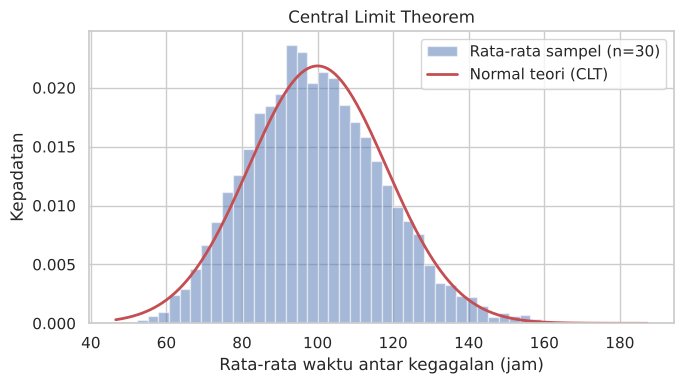

In [ ]:
n_sampel, ulang = 30, 10_000
rata2 = rng.exponential(100, size=(ulang, n_sampel)).mean(axis=1)

print("Mean rata-rata sampel      :", round(rata2.mean(), 2), "(teori 100)")
print("Std rata-rata sampel       :", round(rata2.std(), 2), f"(teori {100/math.sqrt(n_sampel):.2f})")
print("Skewness data asli (expon) :", round(stats.skew(rng.exponential(100, 100_000)), 3), "(teori 2)")
print("Skewness rata-rata sampel  :", round(stats.skew(rata2), 3), "(mendekati 0 = lebih simetris)")

xs = np.linspace(rata2.min(), rata2.max(), 400)
plt.figure(figsize=(7, 4))
plt.hist(rata2, bins=50, density=True, alpha=0.5, label="Rata-rata sampel (n=30)")
plt.plot(xs, norm.pdf(xs, 100, 100/math.sqrt(n_sampel)), "r", lw=2, label="Normal teori (CLT)")
plt.xlabel("Rata-rata waktu antar kegagalan (jam)"); plt.ylabel("Kepadatan"); plt.title("Central Limit Theorem")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretasi:** Data aslinya sangat menceng (skewness ≈2), tetapi rata-rata sampel berukuran 30 sudah jauh lebih simetris (skewness turun drastis) dan mengikuti kurva Normal dengan mean 100 dan simpangan baku ≈18,26.
**Kesimpulan:** Berapa pun bentuk distribusi asal (asal varians berhingga), rata-rata sampel yang cukup besar mendekati Normal. Inilah alasan distribusi Normal dipakai luas dalam statistik inferensial.

---
# Rangkuman Hasil

In [ ]:
print("=== Bagian A: perbandingan hitungan matematis vs Python ===")
display(pd.DataFrame(hasil_prob))
print()
print("=== Bagian B: nilai harapan & varians (teori vs simulasi) ===")
display(pd.DataFrame(ringkasan_dist))

=== Bagian A: perbandingan hitungan matematis vs Python ===


,Soal,Teori (matematis),Python / simulasi,Selisih
0,A1 P(jumlah dua dadu = 7),0.1667,0.1688,0.0022
1,A2 P(Hati atau King),0.3077,0.3102,0.0025
2,A3 P(jumlah=8 | dadu1 genap),0.1667,0.1679,0.0012
3,A4 P(spam | kata 'gratis'),0.8889,0.8876,0.0013
4,A5 P(tepat 2 As dari 5 kartu),0.0399,0.0401,0.0002
5,A6 Monty Hall - strategi tetap,0.3333,0.3347,0.0013
6,A6 Monty Hall - strategi ganti,0.6667,0.6634,0.0033
7,A7 Birthday paradox (n=23),0.5073,0.5087,0.0014



=== Bagian B: nilai harapan & varians (teori vs simulasi) ===


,Distribusi,E[X] teori,E[X] simulasi,Var(X) teori,Var(X) simulasi
0,"Binomial(n=20, p=0.1)",2.0,2.0041,1.8000,1.7951
1,Poisson(lambda=4),4.0,3.9960,4.0000,4.0078
2,Geometrik(p=0.2),5.0,5.0021,20.0000,19.9536
3,"Uniform(0, 10)",5.0,4.9941,8.3333,8.3415
4,Eksponensial(mean=100),100.0,99.9118,10000.0000,9981.7778
5,"Normal(200, 30)",200.0,200.0210,900.0000,901.8163


**Kesimpulan umum**
1. Semua hasil **hitungan matematis** sesuai dengan hasil **Python** (selisih simulasi sangat kecil dan mengecil jika jumlah percobaan diperbesar — Hukum Bilangan Besar).
2. Python memudahkan tiga pendekatan: **enumerasi** (ruang sampel kecil), **fungsi distribusi SciPy** (`pmf/pdf/cdf/sf/ppf`), dan **simulasi** (`rng`), sehingga jawaban bisa saling diverifikasi.
3. Pemilihan distribusi bergantung pada sifat masalah: hitungan sukses dari n percobaan → **Binomial**; kejadian per satuan waktu → **Poisson**; percobaan sampai sukses pertama → **Geometrik**; hasil seragam → **Uniform**; waktu antar kejadian → **Eksponensial**; data simetris di sekitar rata-rata → **Normal**.

---
# Dokumentasi Penggunaan AI

**Nama AI:** Claude (model Claude Sonnet 5.5), dibuat oleh Anthropic
**Tanggal penggunaan:** 1 November 2026

### Prompt yang digunakan
| No | Prompt (ringkasan) | Hasil yang diminta |
|---|---|---|
| 1 | "Aku ada tugas dari dosen, disuruh cari library Python yang bisa digunakan untuk rumus matematika. Temukan berbagai library Python yang relevan untuk menyelesaikan permasalahan probabilitas dan distribusi probabilitas." | Daftar library dan contoh singkat |
| 2 | "Aku mau library-nya yang sesuai dengan perintah: daftar library beserta fungsi dan kegunaannya; setiap permasalahan probabilitas dan distribusi probabilitas sertakan implementasi Python dan interpretasi hasil & kesimpulan; visualisasikan hasil bila relevan. Contohnya yang simpel dulu, yang berkaitan dengan probabilitas dan statistika." | Contoh sederhana + interpretasi + grafik |
| 3 | "Coba cek yang kamu kasih barusan sesuai dengan perintah ini: implementasi pada permasalahan probabilitas (probabilitas, bersyarat, Bayes, kombinasi kejadian, simulasi, bandingkan hitungan matematis dengan Python); implementasi pada distribusi probabilitas (diskrit & kontinu, nilai harapan, varians, simulasi, visualisasi, contoh Teknik Informatika); cantumkan nama AI dan dokumentasikan prompt." | Evaluasi kekurangan jawaban sebelumnya |
| 4 | "Oke bro, buat notebook-nya." | Notebook ini |

### Pemeriksaan kebenaran konsep (verifikasi oleh mahasiswa)
| Hal yang diperiksa | Cara pemeriksaan | Hasil |
|---|---|---|
| Hasil tiap soal | Dibandingkan 3 cara: rumus manual ↔ SciPy ↔ simulasi | Cocok (lihat tabel rangkuman) |
| Kesalahan awal pada kode dadu | Pada versi awal, `P(D % 2 == 0)` di SymPy memberi **0** (salah, seharusnya 1/2) karena operator `%` tidak didukung variabel acak simbolik. Diperbaiki memakai `Or(Eq(D,2), Eq(D,4), Eq(D,6))` | Terkoreksi → 1/2 |
| Parameter SciPy | `expon(scale=1/λ)` — parameter `scale` adalah **mean**, bukan λ; `geom` mulai dari 1; `sf(x)` = P(X > x) | Sudah disesuaikan |
| Interpretasi | Dicek terhadap definisi tiap distribusi (misal Poisson: mean = varians; CLT: skewness turun) | Sesuai teori |

> Catatan: AI hanya membantu menghasilkan contoh kasus dan kode. Mahasiswa bertanggung jawab memahami konsep, menjalankan ulang kode, dan memeriksa hasilnya.